# Feature selection: correlation and multicollinearity

Decides which of the 13 candidate inputs stay in `pnw_model_dataset.csv`.
Uses **training rows only** (split == "train"), so the test years never influence the choice.

Rule agreed with the TA: drop an input only if it is a near-copy of another one,
read as VIF > 10 or |correlation| > 0.9 with another input.
The decision is recorded in `DEFAULT_DROP_INPUTS` in `make_model_dataset.py`.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

from make_model_dataset import INPUT_COLS

## Load the training rows

In [2]:
df = pd.read_csv("pnw_model_dataset.csv", dtype={"gauge_id": str}, parse_dates=["date"])
train = df[df["split"] == "train"]
print(f"{len(train):,} training rows, {train['gauge_id'].nunique()} basins")
print(f"{train['date'].min().date()} to {train['date'].max().date()}")

149,732 training rows, 82 basins
2006-10-01 to 2011-09-30


## Correlation heatmap: the 13 inputs and the target

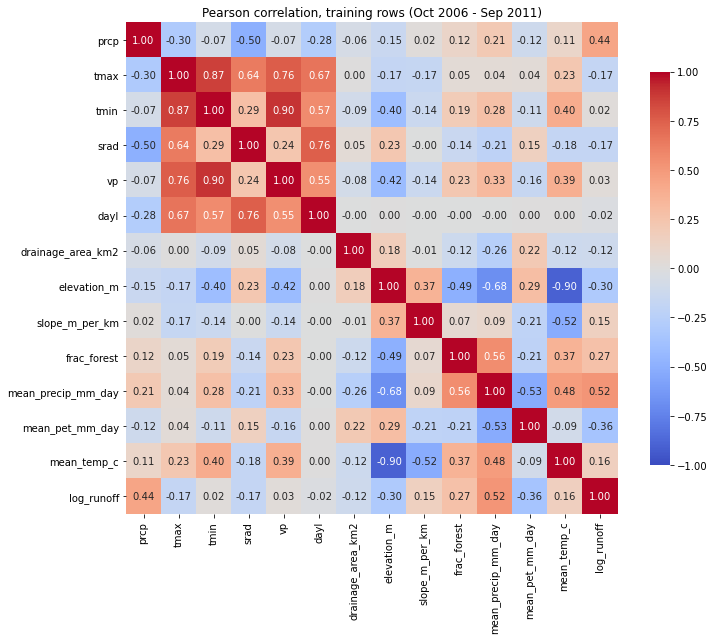

In [3]:
cols = INPUT_COLS + ["log_runoff"]
corr = train[cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation, training rows (Oct 2006 - Sep 2011)")
plt.tight_layout()
plt.show()

## Input pairs with |correlation| > 0.9

In [4]:
pairs = (corr.loc[INPUT_COLS, INPUT_COLS]
         .where(np.triu(np.ones(len(INPUT_COLS), dtype=bool), k=1))
         .stack()
         .rename("corr")
         .reset_index()
         .rename(columns={"level_0": "input_a", "level_1": "input_b"}))
pairs["abs_corr"] = pairs["corr"].abs()
pairs.sort_values("abs_corr", ascending=False).head(10)

,input_a,input_b,corr,abs_corr
67,elevation_m,mean_temp_c,-0.902970,0.902970
24,tmin,vp,0.902030,0.902030
12,tmax,tmin,0.865300,0.865300
14,tmax,vp,0.757982,0.757982
34,srad,dayl,0.757376,0.757376
65,elevation_m,mean_precip_mm_day,-0.684465,0.684465
15,tmax,dayl,0.667163,0.667163
13,tmax,srad,0.637732,0.637732
25,tmin,dayl,0.566173,0.566173
72,frac_forest,mean_precip_mm_day,0.561506,0.561506


## Correlation of each input with the target

In [5]:
corr["log_runoff"].drop("log_runoff").sort_values(key=np.abs, ascending=False).round(3)

mean_precip_mm_day    0.517
prcp                  0.440
mean_pet_mm_day      -0.359
elevation_m          -0.298
frac_forest           0.270
srad                 -0.174
tmax                 -0.173
mean_temp_c           0.159
slope_m_per_km        0.149
drainage_area_km2    -0.117
vp                    0.025
tmin                  0.020
dayl                 -0.017
Name: log_runoff, dtype: float64

## Variance inflation factor (VIF)

VIF measures how well each input can be predicted from the other inputs. 1 = independent; above 10 is the usual
redundancy threshold. Computed on standardized columns so the scale of each input does not matter.

In [6]:
X = train[INPUT_COLS]
X = (X - X.mean()) / X.std()
vif = pd.DataFrame({
    "input": INPUT_COLS,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
}).sort_values("VIF", ascending=False).reset_index(drop=True)
vif.round(2)

,input,VIF
0,tmin,18.48
1,tmax,17.50
2,elevation_m,10.63
3,srad,8.78
4,mean_temp_c,8.14
5,vp,5.93
6,dayl,4.74
7,mean_precip_mm_day,3.35
8,slope_m_per_km,1.84
9,mean_pet_mm_day,1.59


## Decision

Two inputs are near-copies of others and come out. Everything else stays.

| Input | VIF | Strongest partner (abs corr) | Keep or drop | Why |
|---|---|---|---|---|
| tmin | 18.5 | vp (0.90), tmax (0.87) | **drop** | fourth copy of temperature; 0.02 correlation with the target on its own |
| tmax | 17.5 | tmin (0.87) | keep | falls to VIF 5.5 once tmin is gone; stronger target signal (-0.17) |
| elevation_m | 10.6 | mean_temp_c (-0.90) | keep | twice the target correlation of mean_temp_c (-0.30 vs 0.16) |
| mean_temp_c | 8.1 | elevation_m (-0.90) | **drop** | mirror of elevation; high basins are cold |
| all others | < 9 | < 0.76 | keep | |

After dropping `tmin` and `mean_temp_c`, the largest remaining VIF is 5.5 (tmax). Final inputs: 11.

Recorded as `DEFAULT_DROP_INPUTS = ("tmin", "mean_temp_c")` in `make_model_dataset.py`. Random forests and neural
nets tolerate correlated inputs, so this is mainly about a cleaner, defensible input list; keeping all 13 is a
one-argument override (`--drop` with nothing after it).